# Final e2e sweep: contrast and SR vs magnitude

Results of `sweep_final.py` (`results/WFSW/sweep_final_20261108`), z = 30°, seeing 0.9" along the line of sight, magnitudes 7-12 (900 nm).

- **Main figures**: single stage (rMod 0 and 2; WFS at 900 nm for 550 nm, at 1300 nm for 1650 nm), fusion (unmodulated 900 nm + rMod 2 at 1300 nm) and fusion swapped (unmodulated 1300 nm + rMod 2 at 900 nm, chromatic only). Points: mean over the 10 replays (seed and wind directions changed, 5 s) of the configuration selected at that magnitude; error bars: std over the converged replays; `n/N` where runaways were excluded.
- **Equal-flux figures**: both pyramids at one wavelength, 400 nm band split unmod / mod. Not replayed: every curve there, references included, is the sweep value on the nominal realization (paired comparison).
- Ratio panels: each curve over the best single stage at that magnitude. Contrast: mean raw contrast in 2-5 λ/D relative to the integrated AO peak; hollow markers: science SR < 0.25. Dashed / dotted lines: perfect-coronagraph fitting floors at the same conditions.
- **Radial profiles**: raw contrast vs separation at one magnitude (`MAG`, default 7), replay mean ± std, with the perfect-coronagraph bounds: fitting, and fitting + chromatism for a WFS at 900 or 1300 nm.
- Same y range in every contrast panel and in every SR panel.
- Missing cases (still running, or not simulated: achromatic swapped fusion and achromatic 1300 nm single stage) are listed under each figure.

In [1]:
%load_ext autoreload
%autoreload 2
import os.path as op
import pandas as pd
import matplotlib.pyplot as plt
import final_sweep_results as fr

SAVE = False   # True: write the figures as PDF next to the results (fr.OUT)

def show(fig, name):
    if SAVE:
        fig.savefig(op.join(fr.OUT, name + '.pdf'), bbox_inches='tight')
    plt.show()

## Contrast: single, fusion, fusion swapped

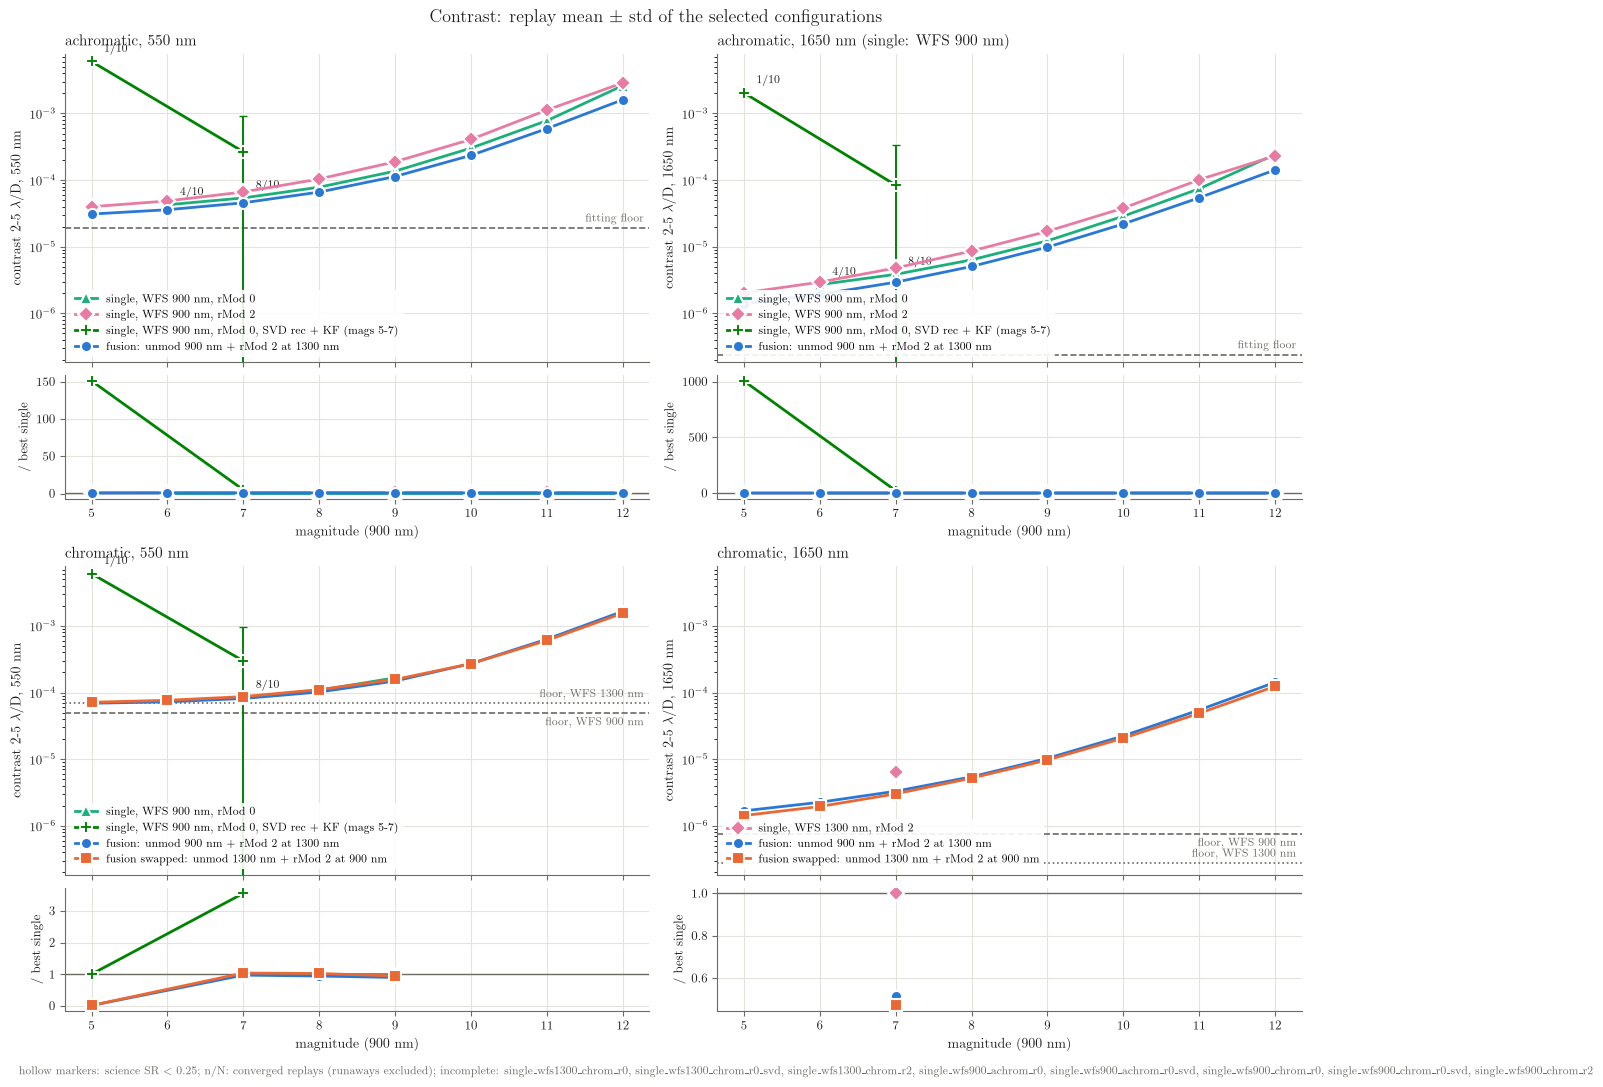

In [2]:
show(fr.plot_main('contrast'), 'contrast_vs_mag')

## SR: single, fusion, fusion swapped

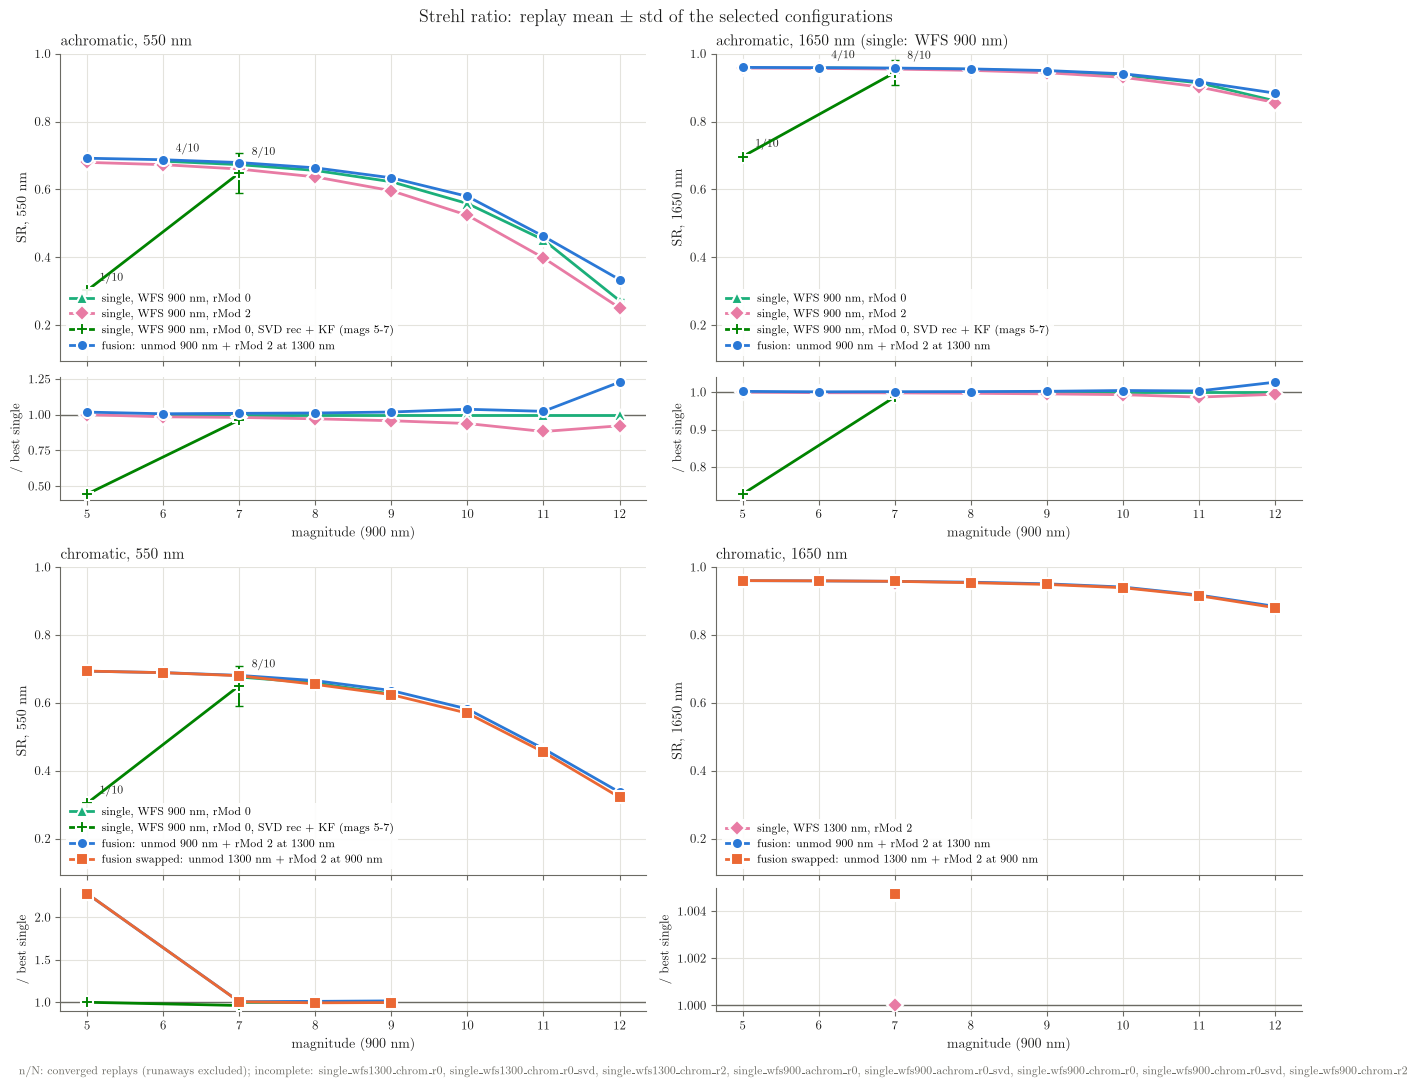

In [3]:
show(fr.plot_main('sr'), 'sr_vs_mag')

## Equal-flux dual: contrast of each band split

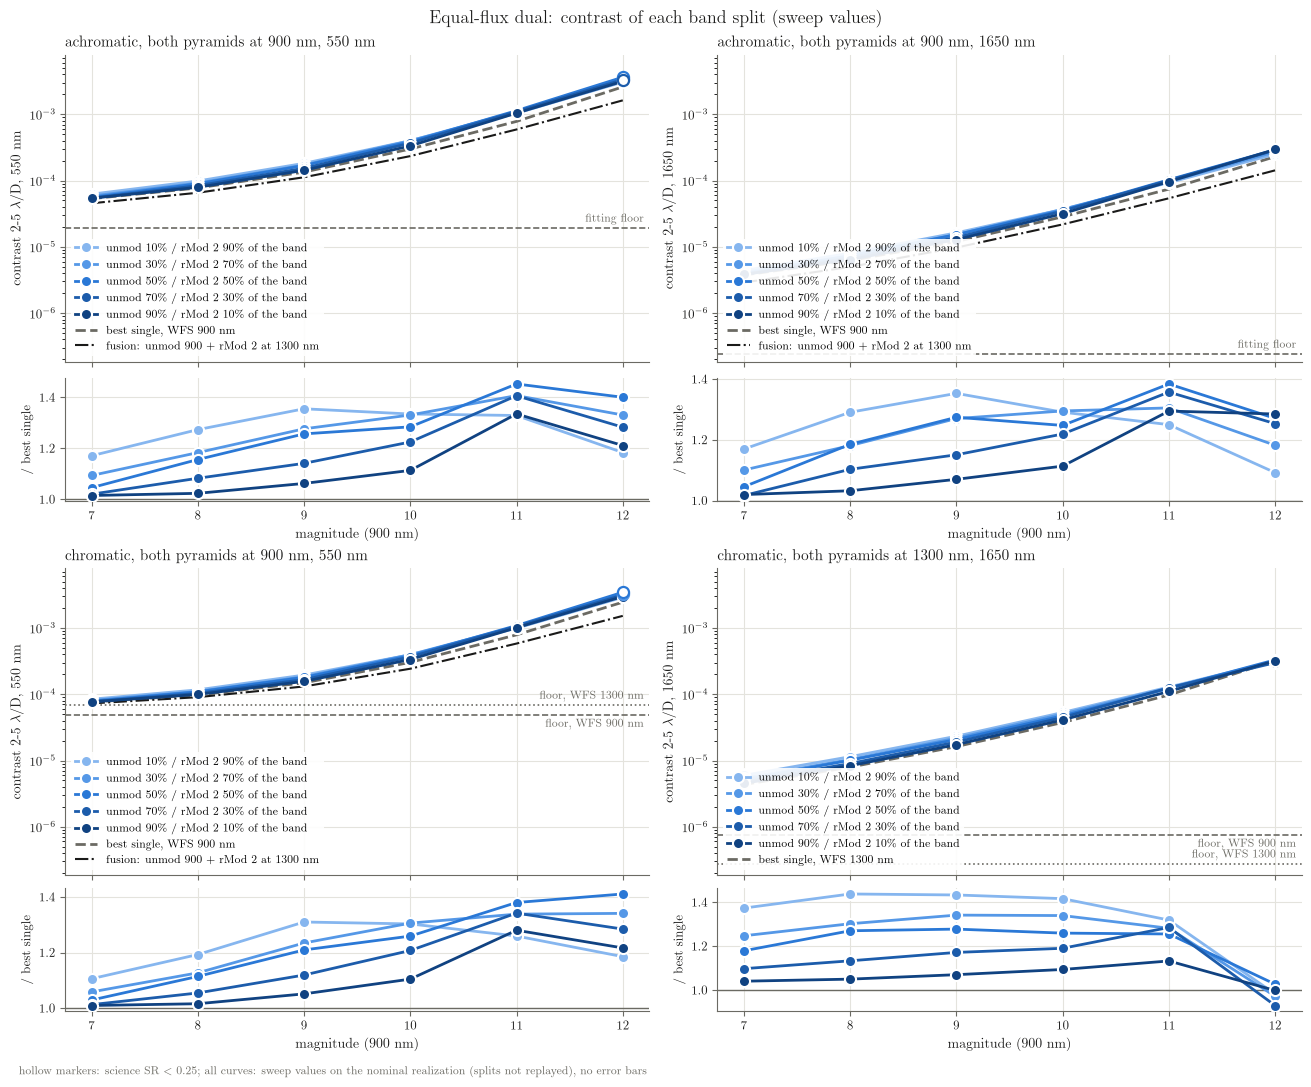

In [4]:
show(fr.plot_equal_flux('contrast'), 'equal_flux_contrast_vs_mag')

## Equal-flux dual: SR of each band split

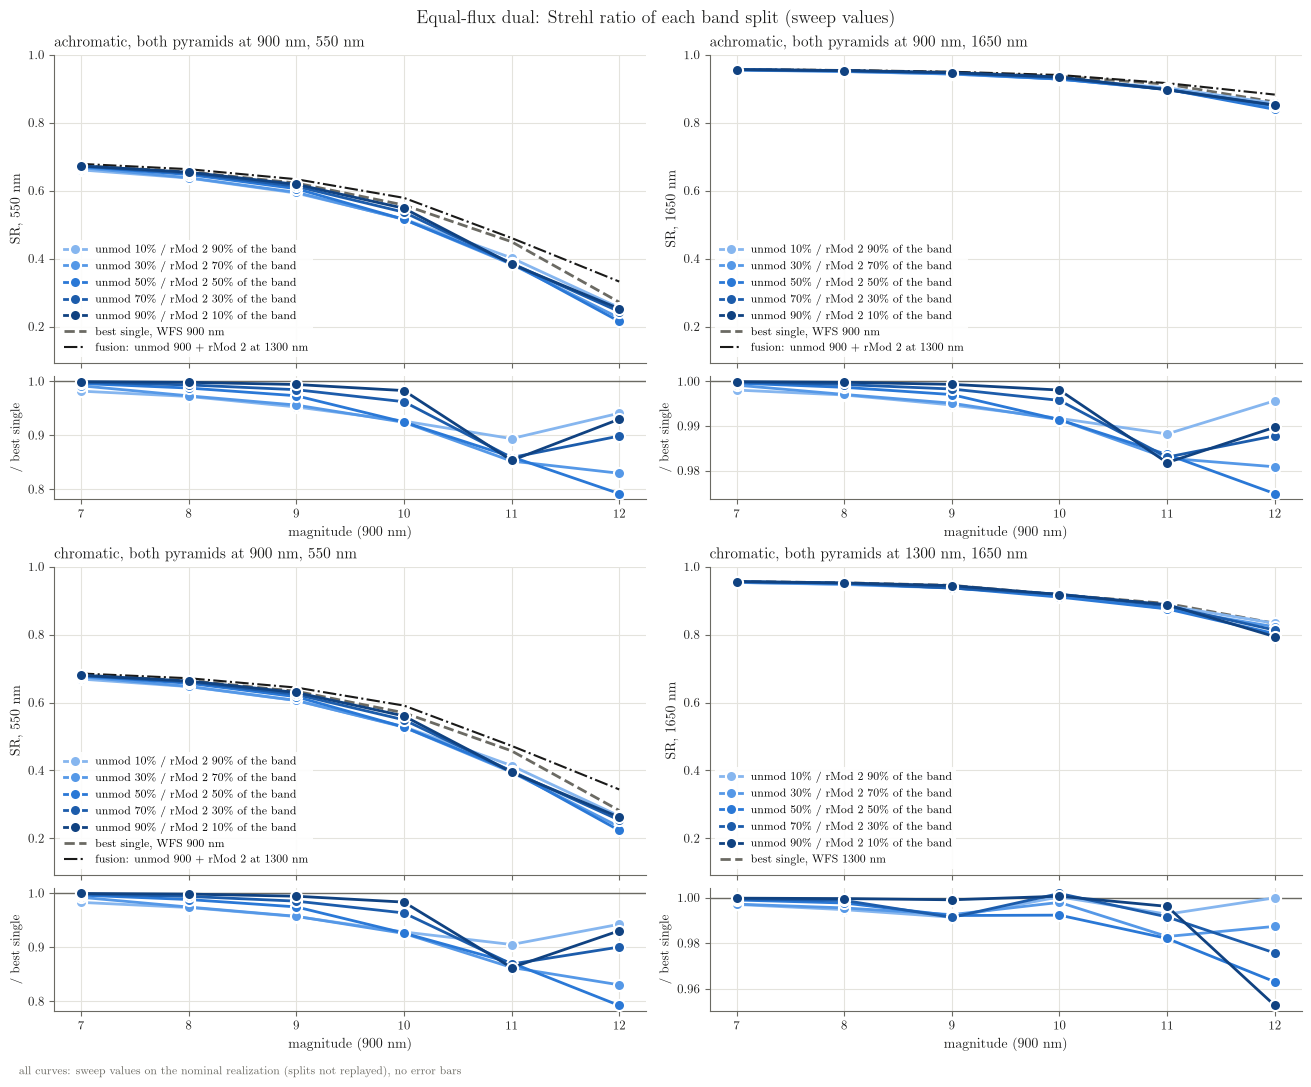

In [5]:
show(fr.plot_equal_flux('sr'), 'equal_flux_sr_vs_mag')

## Radial contrast profiles at one magnitude

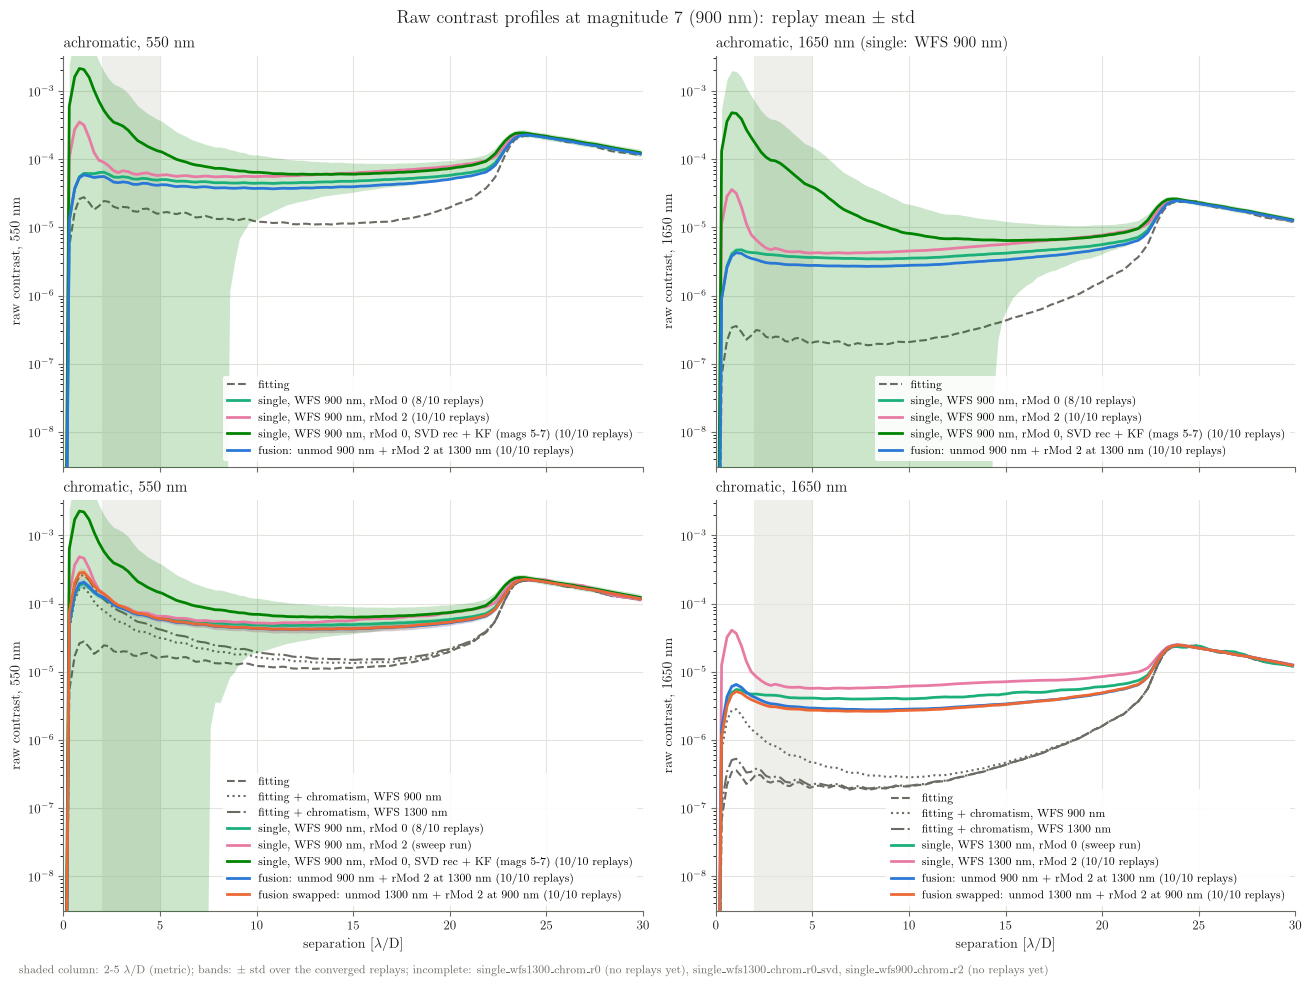

In [6]:
MAG = 7.0   # 900 nm magnitude of the profiles
show(fr.plot_profiles(MAG), f'profiles_mag{MAG:g}')

## Numbers behind the main figures (replay mean, std, converged runs, runaway TNs)

In [7]:
tab = pd.DataFrame(fr.table('contrast')).merge(pd.DataFrame(fr.table('sr')), on=['chromatic', 'band', 'curve', 'case', 'mag', 'n_ok', 'n', 'runaways'],
                                              suffixes=('_contrast', '_sr'))
tab[['chromatic', 'band', 'curve', 'mag', 'mean_contrast', 'std_contrast', 'mean_sr', 'std_sr', 'n_ok', 'n', 'runaways']]

,chromatic,band,curve,mag,mean_contrast,std_contrast,mean_sr,std_sr,n_ok,n,runaways
0,False,550 nm,"single, WFS 900 nm, rMod 0",5.0,NaN,NaN,NaN,NaN,0,10,20261110_055434 20261110_055721 20261110_06000...
1,False,550 nm,"single, WFS 900 nm, rMod 0",6.0,0.000043,1.701744e-06,0.683238,0.002546,4,10,20261110_062146 20261110_062431 20261110_06300...
2,False,550 nm,"single, WFS 900 nm, rMod 0",7.0,0.000054,8.590939e-07,0.672995,0.001778,8,10,20261109_144149 20261109_145246
3,False,550 nm,"single, WFS 900 nm, rMod 0",8.0,0.000078,1.177734e-06,0.655977,0.002052,10,10,
4,False,550 nm,"single, WFS 900 nm, rMod 0",9.0,0.000136,1.441469e-06,0.622643,0.002052,10,10,
...,...,...,...,...,...,...,...,...,...,...,...
88,True,1650 nm,fusion swapped: unmod 1300 nm + rMod 2 at 900 nm,8.0,0.000005,1.720307e-07,0.953927,0.000426,10,10,
89,True,1650 nm,fusion swapped: unmod 1300 nm + rMod 2 at 900 nm,9.0,0.000010,2.581155e-07,0.948884,0.000470,10,10,
90,True,1650 nm,fusion swapped: unmod 1300 nm + rMod 2 at 900 nm,10.0,0.000021,4.245633e-07,0.939159,0.000507,10,10,
91,True,1650 nm,fusion swapped: unmod 1300 nm + rMod 2 at 900 nm,11.0,0.000049,8.137725e-07,0.915654,0.000655,10,10,
